In [7]:
import os
print(os.listdir("data"))

['.gitkeep', '.ipynb_checkpoints', 'aa_dataset-tickets-multi-lang-5-2-50-version.csv']


In [9]:
import pandas as pd
from pathlib import Path

root = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
df = pd.read_csv(root / "data" / "aa_dataset-tickets-multi-lang-5-2-50-version.csv")
print(df.shape)

(28587, 16)


In [10]:
df_en = df[df["language"] == "en"].copy()
print(df_en.shape)
print(df_en[["subject", "body", "queue", "priority"]].isnull().sum())
df_en["queue"].value_counts()
df_en["priority"].value_counts()

(16338, 16)
subject     2607
body           0
queue          0
priority       0
dtype: int64


priority
medium    6618
high      6346
low       3374
Name: count, dtype: int64

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score

data = df_en.dropna(subset=["body", "queue"])
text = data["subject"].fillna("") + " " + data["body"]

X_train, X_test, y_train, y_test = train_test_split(
    text, data["queue"], test_size=0.2, random_state=42, stratify=data["queue"]
)

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Majority-class accuracy:", dummy.score(X_test, y_test))

model = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
pred = model.predict(X_test)
print("Model accuracy:", model.score(X_test, y_test))
print("Macro F1:", f1_score(y_test, pred, average="macro"))

Majority-class accuracy: 0.2897796817625459
Model accuracy: 0.4697062423500612
Macro F1: 0.3665960134751946


In [13]:
from sklearn.metrics import classification_report
print(classification_report(y_test, pred))

                                 precision    recall  f1-score   support

           Billing and Payments       0.88      0.67      0.76       319
               Customer Service       0.37      0.36      0.37       482
                General Inquiry       1.00      0.02      0.04        47
                Human Resources       1.00      0.13      0.23        70
                     IT Support       0.44      0.21      0.28       388
                Product Support       0.39      0.44      0.41       615
          Returns and Exchanges       0.70      0.10      0.17       164
            Sales and Pre-Sales       0.79      0.15      0.25       103
Service Outages and Maintenance       0.78      0.49      0.60       133
              Technical Support       0.44      0.73      0.55       947

                       accuracy                           0.47      3268
                      macro avg       0.68      0.33      0.37      3268
                   weighted avg       0.52      0

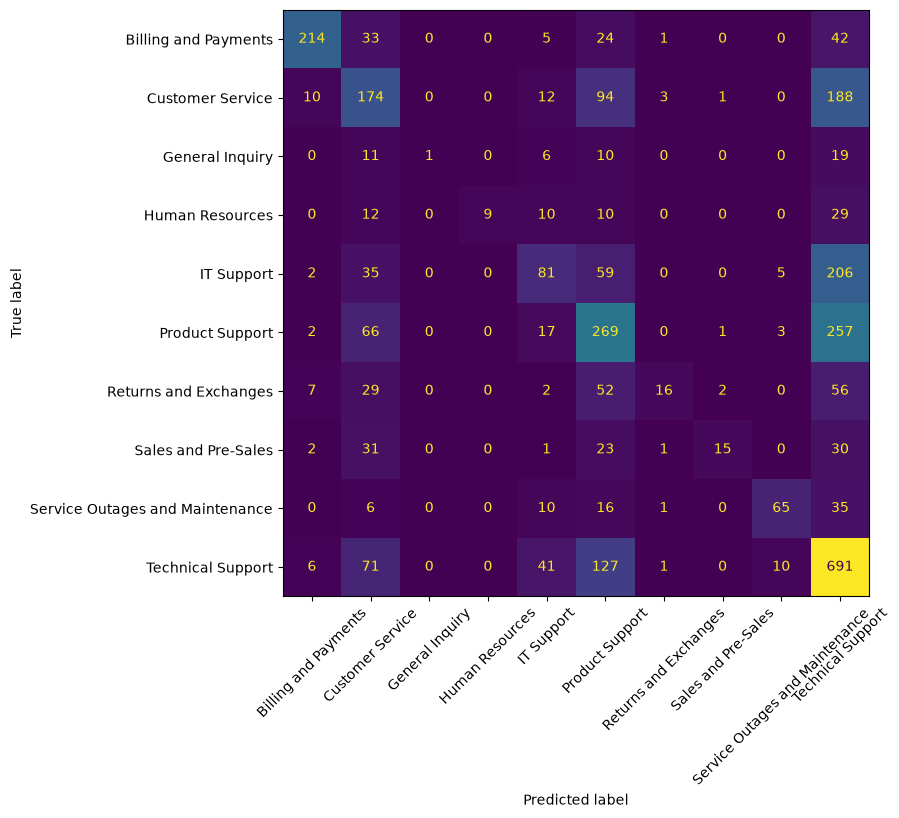

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.show()

In [16]:
df_en["queue"].value_counts()
df_en.duplicated(subset=["subject", "body"]).sum()

np.int64(0)

In [18]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score

def evaluate(name, clf, vec):
    pipe = make_pipeline(vec, clf)
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test)
    return {
        "experiment": name,
        "accuracy": accuracy_score(y_test, p),
        "macro_f1": f1_score(y_test, p, average="macro"),
    }

results = [{"experiment": "Baseline: TF-IDF + LogReg", "accuracy": 0.4697, "macro_f1": 0.3666}]

results.append(evaluate(
    "LogReg + balanced weights",
    LogisticRegression(max_iter=1000, class_weight="balanced"),
    TfidfVectorizer()))

results.append(evaluate(
    "+ word pairs, min_df=2, sublinear_tf",
    LogisticRegression(max_iter=1000, class_weight="balanced"),
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)))

results.append(evaluate(
    "LinearSVC, balanced",
    LinearSVC(class_weight="balanced"),
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)))

pd.DataFrame(results).round(3)

,experiment,accuracy,macro_f1
0,Baseline: TF-IDF + LogReg,0.470,0.367
1,LogReg + balanced weights,0.427,0.420
2,"+ word pairs, min_df=2, sublinear_tf",0.529,0.542
3,"LinearSVC, balanced",0.685,0.698


In [19]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report

pipe = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    LinearSVC(class_weight="balanced"),
)

search = GridSearchCV(
    pipe,
    {"linearsvc__C": [0.1, 0.3, 1, 3]},
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
)
search.fit(X_train, y_train)

print("Best settings:", search.best_params_)
print("Cross-validated macro F1:", round(search.best_score_, 3))

best = search.best_estimator_
pred = best.predict(X_test)
print(classification_report(y_test, pred))

Best settings: {'linearsvc__C': 3}
Cross-validated macro F1: 0.681
                                 precision    recall  f1-score   support

           Billing and Payments       0.85      0.87      0.86       319
               Customer Service       0.66      0.69      0.67       482
                General Inquiry       0.86      0.64      0.73        47
                Human Resources       0.84      0.67      0.75        70
                     IT Support       0.64      0.62      0.63       388
                Product Support       0.67      0.66      0.67       615
          Returns and Exchanges       0.73      0.63      0.68       164
            Sales and Pre-Sales       0.71      0.65      0.68       103
Service Outages and Maintenance       0.79      0.80      0.80       133
              Technical Support       0.70      0.74      0.72       947

                       accuracy                           0.71      3268
                      macro avg       0.74      0.70   

In [20]:
results.append({
    "experiment": "LinearSVC C=3 (tuned with 5-fold CV)",
    "accuracy": accuracy_score(y_test, pred),
    "macro_f1": f1_score(y_test, pred, average="macro"),
})
pd.DataFrame(results).round(3)

,experiment,accuracy,macro_f1
0,Baseline: TF-IDF + LogReg,0.470,0.367
1,LogReg + balanced weights,0.427,0.420
2,"+ word pairs, min_df=2, sublinear_tf",0.529,0.542
3,"LinearSVC, balanced",0.685,0.698
4,LinearSVC C=3 (tuned with 5-fold CV),0.707,0.718


In [21]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr = vec.fit_transform(X_train)
Xte = vec.transform(X_test)

max_sim = np.concatenate([
    cosine_similarity(Xte[i:i + 500], Xtr).max(axis=1)
    for i in range(0, Xte.shape[0], 500)
])

print(pd.Series(max_sim).describe().round(3))
print("Share of test tickets with a near-copy (similarity > 0.8) in train:",
      round((max_sim > 0.8).mean(), 3))

mask = max_sim <= 0.8
y_arr = y_test.values
print("Accuracy on all test tickets:   ", round((pred == y_arr).mean(), 3))
print("Accuracy on 'novel' tickets only:", round((pred[mask] == y_arr[mask]).mean(), 3))

count    3268.000
mean        0.568
std         0.217
min         0.152
25%         0.353
50%         0.616
75%         0.748
max         0.987
dtype: float64
Share of test tickets with a near-copy (similarity > 0.8) in train: 0.151
Accuracy on all test tickets:    0.707
Accuracy on 'novel' tickets only: 0.656
